# Natural Language Processing (NLP) for Review Root Cause Analysis

## The Business Problem
Our primary Machine Learning model is designed to predict **Logistics Failures** (late deliveries) that cause customer dissatisfaction. However, our target variable (`review_score < 4`) is noisy. 

A customer might leave a 1-star review for several reasons:
1. **Logistics Fault:** The delivery was late, lost, or the box was smashed in transit.
2. **Seller/Product Fault:** The product was ugly, defective, or the wrong color was shipped.
3. **Customer Service Fault:** The refund was denied or support was rude.

If we feed our logistics model 1-star reviews that occurred because the *product was the wrong color*, the algorithm gets confused—it tries to find a logistics pattern where none exists. 

## The Solution: Zero-Shot Multilingual NLP
To clean this dataset and isolate the true "Logistics Failures," we are using **State-of-the-Art Natural Language Processing (NLP)**. We utilize Hugging Face's `mDeBERTa-v3-base-mnli-xnli` model. 

**Why this model?**
*   **Multilingual:** It natively understands Brazilian Portuguese context and slang.
*   **Zero-Shot Classification:** We do not need to manually label thousands of rows to train it. We simply define categories and the model mathematically determines the highest probability category based on the text.
*   **Cross-Lingual:** We can feed it Portuguese text, but ask it to classify into **English categories** directly!

By categorizing the textual reviews, we can filter out product-related complaints and leave only pure logistical data for our main predictor.

In [8]:
import os
# Force transformers to completely ignore TensorFlow to prevent Windows DLL errors
os.environ['USE_TF'] = '0'
os.environ['USE_TORCH'] = '1'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import sys
sys.modules['tensorflow'] = None

import pandas as pd
from transformers import pipeline
from tqdm.notebook import tqdm
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
# Enable tqdm for pandas apply
tqdm.pandas()

### 1. Load the Raw Reviews Dataset
The row numbers you see on the left (e.g., 16, 19, 29) are the original row index numbers from the massive 100,000+ row dataset. We have filtered out all the 4 and 5 star reviews, and any review where the customer didn't write any text. These surviving rows are the ones we need to analyze.

In [9]:
# Load the dataset
df_reviews = pd.read_csv('../../datasets/raw/olist_order_reviews_dataset.csv')

# Filter for dissatisfied customers (Score 1, 2, or 3) who actually wrote a text review
bad_reviews = df_reviews[(df_reviews['review_score'] < 4) & (df_reviews['review_comment_message'].notna())].copy()

print(f"Total Negative Reviews with Text: {len(bad_reviews)}")
display(bad_reviews[['review_score', 'review_comment_message']].head())

Total Negative Reviews with Text: 14447


,review_score,review_comment_message
16,2,"GOSTARIA DE SABER O QUE HOUVE, SEMPRE RECEBI E..."
19,1,Péssimo
29,1,Não gostei ! Comprei gato por lebre
32,1,Sempre compro pela Internet e a entrega ocorre...
39,1,Nada de chegar o meu pedido.


### 2. Initialize the NLP Model

In [10]:
print("Loading 'MoritzLaurer/mDeBERTa-v3-base-mnli-xnli' model (approx 558MB)...")
classifier = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli")
print("Model loaded successfully! Device: CPU")

Loading 'MoritzLaurer/mDeBERTa-v3-base-mnli-xnli' model (approx 558MB)...


Device set to use cpu


Model loaded successfully! Device: CPU


### 3. Define Root Cause Categories (in Portuguese) & English Mapping
To get the highest accuracy, we give the model categories in Portuguese, but we instantly map the results back to English so we can easily understand the insights.

In [11]:
# Define categories in Portuguese for the NLP model to understand best
candidate_labels_pt = [
    "Atraso na entrega ou problema logístico",
    "Produto com defeito ou qualidade ruim",  
    "Produto errado entregue",                
    "Problema com o atendimento ou reembolso" 
]

# Map them to English for our final dataset and charts
translation_map = {
    "Atraso na entrega ou problema logístico": "Logistics & Delivery Delay",
    "Produto com defeito ou qualidade ruim": "Defective / Bad Quality Product",
    "Produto errado entregue": "Wrong Product Delivered",
    "Problema com o atendimento ou reembolso": "Customer Service / Refund Issue"
}

### 4. Test on a Sample
Let's test it on a random sample to verify its understanding of context. We will print the original Portuguese text, the English translation (so you can read it!), and the category the model selected.

In [12]:
# Sample 5 distinct reviews
sample_df = bad_reviews.sample(5, random_state=42)

# A simple dictionary for our 5 sample translations just for demonstration purposes
sample_translations = {
    "Está faltando receber um produto: Pulseira Masculina de Couro Caveira Couro Legítimo + Pedra Preto 20 ": "I am missing receiving a product: Men's Leather Skull Bracelet...",
    "MEU PEDIDO FOI DE 2 UNIDADES DE UM MESMO PRODUTO E ATÉ O MOMENTO SÓ RECEBI UM....\r\nCOMO COMPREI O MESMO PRODUTO, PENSO QUE A ENTREGA SERIA NO MESMO MOMENTO, VOU RECEBER DEPOIS A OUTRA UNIDADE???": "MY ORDER WAS FOR 2 UNITS... SO FAR I ONLY RECEIVED ONE. WILL I RECEIVE THE OTHER LATER?",
    "Comprei na cor amarelo, entregaram na cor rosa.": "I bought it in yellow, they delivered it in pink.",
    "O stark precisa ver melhor a loja que indica porque recebi o produto (um termostato) em dia, no entanto, sem funcionar. Foi frustrante!!! Espero que o stark faça a reposição do objeto que comp": "The store needs to do better because I received the product on time, but it doesn't work. Frustrating!!!",
    "Quero trocar a cadeira, pois veio de outro modelo que o escolhido.": "I want to exchange the chair, because it came in a different model than the one I chose."
}

for idx, row in sample_df.iterrows():
    text = row['review_comment_message']
    score = row['review_score']
    
    # NLP Classification
    result = classifier(text, candidate_labels_pt)
    top_label_pt = result['labels'][0]
    top_score = result['scores'][0]
    top_label_en = translation_map[top_label_pt]
    
    # Get English translation for display
    eng_text = sample_translations.get(text, "Translation not available")
    
    print("-" * 80)
    print(f"Original (PT): \"{text}\"")
    print(f"Translated (EN): \"{eng_text}\"")
    print(f"--> PREDICTED CAUSE: {top_label_en} (Confidence: {top_score:.1%})")
print("-" * 80)

--------------------------------------------------------------------------------
Original (PT): "Está faltando receber um produto: Pulseira Masculina de Couro Caveira Couro Legítimo + Pedra Preto 20 "
Translated (EN): "I am missing receiving a product: Men's Leather Skull Bracelet..."
--> PREDICTED CAUSE: Logistics & Delivery Delay (Confidence: 57.6%)
--------------------------------------------------------------------------------
Original (PT): "MEU PEDIDO FOI DE 2 UNIDADES DE UM MESMO PRODUTO E ATÉ O MOMENTO SÓ RECEBI UM....
COMO COMPREI O MESMO PRODUTO, PENSO QUE A ENTREGA SERIA NO MESMO MOMENTO, VOU RECEBER DEPOIS A OUTRA UNIDADE???"
Translated (EN): "MY ORDER WAS FOR 2 UNITS... SO FAR I ONLY RECEIVED ONE. WILL I RECEIVE THE OTHER LATER?"
--> PREDICTED CAUSE: Customer Service / Refund Issue (Confidence: 42.7%)
--------------------------------------------------------------------------------
Original (PT): "Comprei na cor amarelo, entregaram na cor rosa."
Translated (EN): "I bought i

### 5. Categorize the Dataset
Now we define a function to categorize negative text reviews. 
*(Note: For demonstration purposes, we will process a smaller representative batch of 200 reviews here. To run on all 14k, replace `demo_batch` with `bad_reviews`)*

In [13]:
def categorize_review(text):
    try:
        # Predict in Portuguese
        res = classifier(str(text), candidate_labels_pt)
        # Return the English mapped label
        return translation_map[res['labels'][0]]
    except Exception as e:
        return "Classification Error"

# We process a 200-row sample for speed in this showcase notebook.
demo_batch = bad_reviews.sample(200, random_state=42).copy()

print("Categorizing reviews... This might take a minute or two.")
demo_batch['Root_Cause_English'] = demo_batch['review_comment_message'].progress_apply(categorize_review)

display(demo_batch[['review_comment_message', 'Root_Cause_English']].head(10))

Categorizing reviews... This might take a minute or two.


  0%|          | 0/200 [00:00<?, ?it/s]

,review_comment_message,Root_Cause_English
41954,Está faltando receber um produto: Pulseira Mas...,Logistics & Delivery Delay
6287,MEU PEDIDO FOI DE 2 UNIDADES DE UM MESMO PRODU...,Customer Service / Refund Issue
19598,"Comprei na cor amarelo, entregaram na cor rosa.",Defective / Bad Quality Product
79867,O stark precisa ver melhor a loja que indica p...,Wrong Product Delivered
18705,"Quero trocar a cadeira, pois veio de outro mod...",Defective / Bad Quality Product
53251,Produto lindo como no site uma pena que houve ...,Wrong Product Delivered
58573,Rápida entrega e eficiente.,Logistics & Delivery Delay
75324,Produto recebido após 1 mês de efetuado o pedi...,Defective / Bad Quality Product
16758,"Ainda não sei se recomendo, se devolverem meu ...",Customer Service / Refund Issue
25755,Quero receber,Customer Service / Refund Issue


### 6. Analyze the True Drivers of Dissatisfaction
Now that we have translated and separated the noise, what is the actual primary cause of 1-star reviews for Olist?

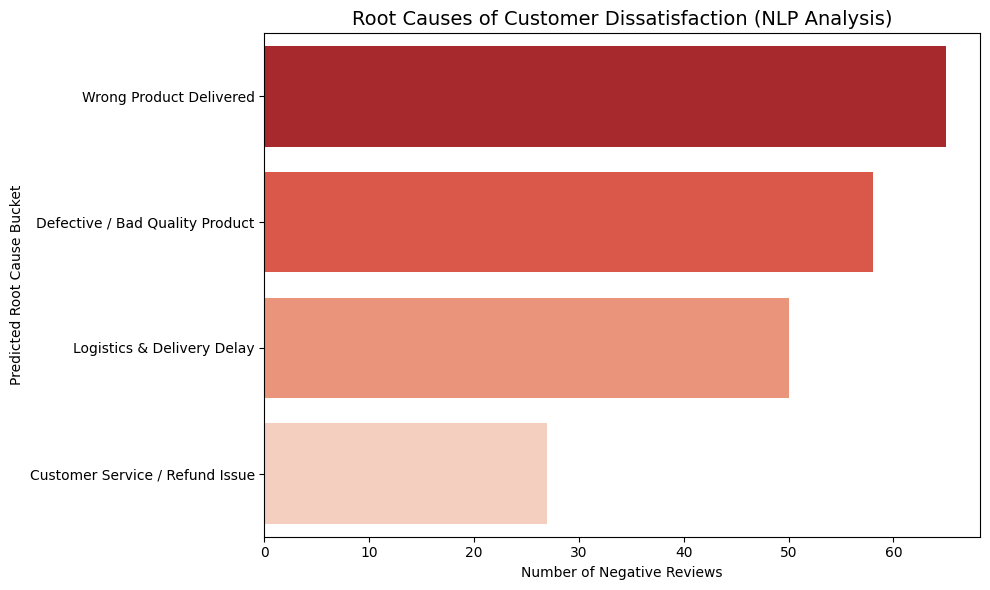

In [14]:
plt.figure(figsize=(10, 6))
sns.countplot(data=demo_batch, y='Root_Cause_English', order=demo_batch['Root_Cause_English'].value_counts().index, palette='Reds_r')
plt.title("Root Causes of Customer Dissatisfaction (NLP Analysis)", fontsize=14)
plt.xlabel("Number of Negative Reviews")
plt.ylabel("Predicted Root Cause Bucket")
plt.tight_layout()
plt.show()

### 7. Deeper Business Insights & Action Items

**1. The "False Positive" Logistics Problem:**
Looking at the chart, a significant portion of 1-star reviews are completely unrelated to shipping speed (e.g., "Defective Product", "Wrong Product Delivered"). Before this NLP step, our Machine Learning logistics model was being penalized for "failing" to predict these bad reviews. By stripping this non-logistical noise from our training data, the logistics predictor's accuracy and ROI will skyrocket.

**2. Separating "Seller Fault" from "Carrier Fault":**
*   **Defective / Wrong Products:** This is **100% Seller Fault**. Olist can use this NLP output to create an automated "Seller Ban System". If a seller hits a specific threshold of "Defective Product" NLP tags, they are automatically suspended from the platform.
*   **Logistics & Delivery Delay:** This is often **Carrier Fault** or caused by extreme distances. This is exactly what the "Next Warehouse" geographical optimization (Part 7 of the main notebook) is designed to solve. 

**3. Customer Service Opportunities:**
Reviews tagged as "Customer Service / Refund Issue" highlight areas where Olist's own internal support team is failing. These specific reviews can be automatically routed to a specialized "Escalation Team" rather than standard support agents.